# Atividade 2 — Regressão linear com várias variáveis: preço de casas na Califórnia

Ponto de partida: notebook 2.6 (salários). Aqui são 8 variáveis de entrada, entao o modelo vira `nn.Linear(8, 1)`.

## Importação das bibliotecas

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

import torch
from torch import nn, optim

torch.manual_seed(1234)
np.random.seed(1234)

## Dados

O dataset California Housing vem no scikit-learn. Cada linha é um quarteirão (block group) do censo de 1990 da Califórnia e o alvo é o preço mediano das casas, em centenas de milhares de dólares.

In [2]:
dados = fetch_california_housing(as_frame=True)
X, y = dados.data, dados.target
print('X:', X.shape, ' y:', y.shape)
X.head()

X: (20640, 8)  y: (20640,)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25


### O que cada variável significa

- **MedInc**: renda mediana das familias do quarteirão (em dezenas de milhares de dólares)
- **HouseAge**: idade mediana das casas (anos)
- **AveRooms**: media de comodos por domicilio
- **AveBedrms**: media de quartos por domicilio
- **Population**: população do quarteirão
- **AveOccup**: media de moradores por domicilio
- **Latitude** e **Longitude**: localização do quarteirão
- **MedHouseVal** (alvo): preço mediano das casas, em centenas de milhares de dólares (o maximo é cortado em 5, ou seja US$ 500 mil)

In [3]:
df = X.copy()
df['MedHouseVal'] = y
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


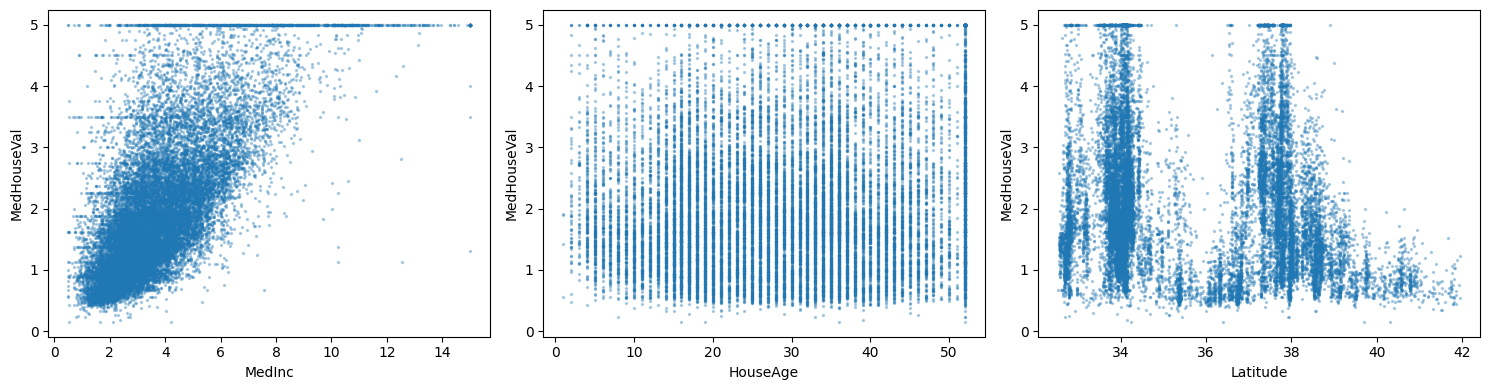

In [4]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axs, ['MedInc', 'HouseAge', 'Latitude']):
    ax.scatter(df[col], df['MedHouseVal'], s=2, alpha=0.3)
    ax.set_xlabel(col)
    ax.set_ylabel('MedHouseVal')
plt.tight_layout()
plt.show()

No describe da pra ver que AveRooms, AveBedrms, Population e AveOccup tem uns valores bem extremos (o max é muito maior que a media, tipo AveOccup com max de 1243). O preço tem teto em 5 (US$ 500 mil), por isso aparece aquela linha reta em cima dos graficos.

Nos graficos, a renda (MedInc) é a variavel mais ligada ao preço, quanto maior a renda maior o preço. A idade da casa (HouseAge) quase nao mostra relação. Na latitude aparecem dois grupos com preço mais alto, perto de 34 (região de Los Angeles) e de 38 (região de San Francisco).

### Treino, validação e teste (70/15/15)

In [5]:
x_raw = X.to_numpy()
y_raw = y.to_numpy().reshape(-1, 1)

x_train_raw, x_temp_raw, y_train_raw, y_temp_raw = train_test_split(
    x_raw, y_raw, test_size=0.3, random_state=42)
x_val_raw, x_test_raw, y_val_raw, y_test_raw = train_test_split(
    x_temp_raw, y_temp_raw, test_size=0.5, random_state=42)
print('treino:', x_train_raw.shape, ' validação:', x_val_raw.shape, ' teste:', x_test_raw.shape)

treino: (14448, 8)  validação: (3096, 8)  teste: (3096, 8)


### Padronização

O `StandardScaler` é ajustado (`fit`) só no treino e depois aplicado na validação e no teste, pra nao vazar informação.

In [6]:
x_scaler = StandardScaler().fit(x_train_raw)
y_scaler = StandardScaler().fit(y_train_raw)

x_train = torch.from_numpy(x_scaler.transform(x_train_raw)).float()
y_train = torch.from_numpy(y_scaler.transform(y_train_raw)).float()
x_val = torch.from_numpy(x_scaler.transform(x_val_raw)).float()
y_val = torch.from_numpy(y_scaler.transform(y_val_raw)).float()
x_test = torch.from_numpy(x_scaler.transform(x_test_raw)).float()
y_test = torch.from_numpy(y_scaler.transform(y_test_raw)).float()
print('x_train:', x_train.shape, ' y_train:', y_train.shape)

x_train: torch.Size([14448, 8])  y_train: torch.Size([14448, 1])


## Modelo

`nn.Linear(8, 1)`: 8 pesos (um por variavel) e 1 bias.

In [7]:
model = nn.Linear(8, 1)
print('weight:', model.weight.shape, ' bias:', model.bias.shape)

weight: torch.Size([1, 8])  bias: torch.Size([1])


## Treinamento

Mesmo esquema do 2.6: `nn.MSELoss`, `optim.SGD` e as funções `train_epoch` e `validate_epoch`. Cada epoca usa o treino inteiro de uma vez.

In [8]:
lr = 0.1
n_epochs = 1000
criterion = nn.MSELoss()
optimizer = optim.SGD(model.parameters(), lr=lr)

In [9]:
def train_epoch(model, optimizer, criterion, x_train, y_train):
    model.train()
    optimizer.zero_grad()
    y_pred = model(x_train)
    loss = criterion(y_pred, y_train)
    loss.backward()
    optimizer.step()
    return loss.item()


def validate_epoch(model, criterion, x_val, y_val):
    model.eval()
    with torch.no_grad():
        y_pred = model(x_val)
        loss = criterion(y_pred, y_val)
    return loss.item()

In [10]:
train_losses = []
val_losses = []

for epoch in range(n_epochs):
    train_losses.append(train_epoch(model, optimizer, criterion, x_train, y_train))
    val_losses.append(validate_epoch(model, criterion, x_val, y_val))
    if (epoch + 1) % 100 == 0:
        print(f'Epoch[{epoch + 1}/{n_epochs}], Train Loss: {train_losses[-1]:.6f}, Val Loss: {val_losses[-1]:.6f}')

Epoch[100/1000], Train Loss: 0.393754, Val Loss: 0.406560
Epoch[200/1000], Train Loss: 0.390795, Val Loss: 0.403884
Epoch[300/1000], Train Loss: 0.390663, Val Loss: 0.403760
Epoch[400/1000], Train Loss: 0.390655, Val Loss: 0.403742
Epoch[500/1000], Train Loss: 0.390654, Val Loss: 0.403735
Epoch[600/1000], Train Loss: 0.390654, Val Loss: 0.403732
Epoch[700/1000], Train Loss: 0.390654, Val Loss: 0.403731
Epoch[800/1000], Train Loss: 0.390654, Val Loss: 0.403730
Epoch[900/1000], Train Loss: 0.390654, Val Loss: 0.403730
Epoch[1000/1000], Train Loss: 0.390654, Val Loss: 0.403730


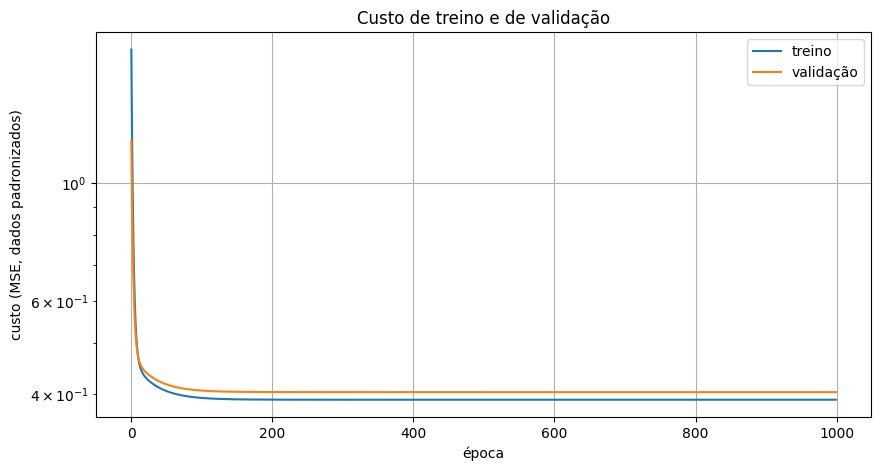

In [11]:
plt.figure(figsize=(10, 5))
plt.plot(train_losses, label='treino')
plt.plot(val_losses, label='validação')
plt.yscale('log')
plt.xlabel('época')
plt.ylabel('custo (MSE, dados padronizados)')
plt.title('Custo de treino e de validação')
plt.legend()
plt.grid(True)
plt.show()

## Avaliação no teste

RMSE em dólares: a previsão volta pra escala original com `inverse_transform` e é multiplicada por 100.000. O baseline sempre chuta o preço médio do treino.

In [12]:
model.eval()
with torch.no_grad():
    y_test_pred = y_scaler.inverse_transform(model(x_test).numpy())

rmse_test = np.sqrt(np.mean((y_test_pred - y_test_raw) ** 2)) * 100000
y_base = np.full_like(y_test_raw, y_train_raw.mean())
rmse_base = np.sqrt(np.mean((y_base - y_test_raw) ** 2)) * 100000
print(f'RMSE do modelo no teste:        US$ {rmse_test:,.0f}')
print(f'RMSE do baseline (média treino): US$ {rmse_base:,.0f}')
print(f'preço médio no teste:            US$ {y_test_raw.mean() * 100000:,.0f}')

RMSE do modelo no teste:        US$ 72,129
RMSE do baseline (média treino): US$ 114,992
preço médio no teste:            US$ 206,596


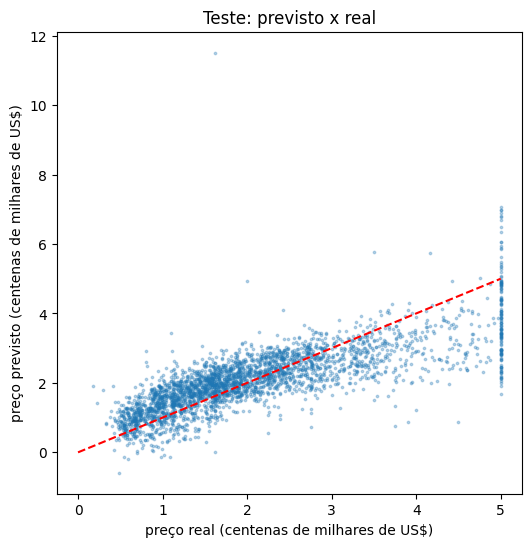

In [13]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test_raw, y_test_pred, s=3, alpha=0.3)
plt.plot([0, 5], [0, 5], 'r--')
plt.xlabel('preço real (centenas de milhares de US$)')
plt.ylabel('preço previsto (centenas de milhares de US$)')
plt.title('Teste: previsto x real')
plt.show()

No teste o modelo erra em media uns US$ 72 mil (RMSE de US$ 72.129), enquanto o baseline que sempre chuta a media do treino erra uns US$ 115 mil (US$ 114.992). Entao a regressão reduz o erro em uns 37% em relação ao chute. Mas perto do preço medio do teste (uns US$ 207 mil) o erro ainda é grande. No grafico da pra ver que as casas no teto de 500 mil ficam bem subestimadas e algumas casas baratas recebem até preço negativo.

### Os 8 pesos aprendidos

Latitude     -0.772254
Longitude    -0.750449
AveRooms     -0.258815
AveOccup     -0.036026
Population   -0.000764
HouseAge      0.105508
AveBedrms     0.301019
MedInc        0.733702
dtype: float32
bias: 1.0254473714610413e-08


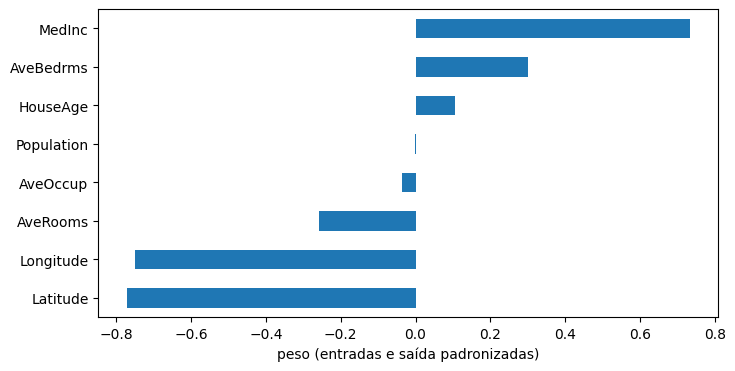

In [14]:
pesos = pd.Series(model.weight.detach().numpy()[0], index=X.columns).sort_values()
print(pesos)
print('bias:', model.bias.item())
pesos.plot.barh(figsize=(8, 4))
plt.xlabel('peso (entradas e saída padronizadas)')
plt.show()

As que mais aumentam o preço previsto sao MedInc (0.73) e depois AveBedrms (0.30) e HouseAge (0.11). As que mais diminuem sao Latitude (-0.77) e Longitude (-0.75), ou seja quanto mais pro norte e mais pro leste (mais longe da costa) mais barato, e depois AveRooms (-0.26). Population e AveOccup ficaram quase zero. O AveRooms negativo com o AveBedrms positivo parece estranho, mas é porque as duas andam muito juntas, entao o modelo divide o efeito entre elas.

So faz sentido comparar os pesos entre si porque as entradas foram padronizadas: todas ficaram com media 0 e desvio padrao 1, entao cada peso diz quanto o preço previsto muda (em desvios padrao) quando a variavel sobe 1 desvio padrao. Sem padronizar o peso ia depender da unidade de cada variavel (renda em dezenas de milhares, idade em anos, população em pessoas) e um peso pequeno ou grande podia ser só por causa da escala.

## Conclusão

O modelo é bem melhor que o baseline, mas pra prever preço de casa ainda nao é bom o suficiente, errar uns US$ 72 mil em media é muito (mais de um terço do preço medio). Uma reta nao pega bem a relação com a localização, o preço tem teto em 500 mil e tem outliers.

Pra melhorar eu tentaria uma rede com camadas escondidas (nao linear), criar features novas como distancia da costa ou das cidades grandes e combinações de latitude e longitude, tratar os outliers (ou usar log nas variaveis mais assimetricas) e tirar ou tratar as casas no teto de 500 mil.